# Gradient Descent

-> An optimization technique to improve the performance of machine learning and neural network models by utilizing derivatives.

## Types of Gradient Descent: 

i - Batch GD<br>
ii - Stochastic GD<br>
iii - Mini Batch GD<br>

In [65]:
# importing necessary libraries 
import pandas as pd 
import tensorflow 
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import time
import matplotlib.pyplot as plt

In [51]:
# importing data 
df = pd.read_csv('Social_Network_Ads.csv') 
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [52]:
# seperating X and Y 
X = df.iloc[:,1:4]
Y = df.iloc[:,-1]

In [53]:
# Encoding categorical column 'Gender'
X = pd.get_dummies(X,columns=['Gender'],drop_first=True)
X

,Age,EstimatedSalary,Gender_Male
0,19,19000,True
1,35,20000,True
2,26,43000,False
3,27,57000,False
4,19,76000,True
...,...,...,...
395,46,41000,False
396,51,23000,True
397,50,20000,False
398,36,33000,True


In [54]:
# splitting the data into training and testing part 
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=1) 

In [55]:
# scaling the data in X_train and X_test
scaler = StandardScaler() 
X_train_scaled = X_train.copy() 
X_test_scaled = X_test.copy() 

# Determining columns to be scaled 
scale_cols = ['Age', 'EstimatedSalary']

# scaling the data
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

### i- Batch GD

-> Number of weight updates = Number of epochs<br>
-> Can take large number of epochs to converge

In [56]:
batch_model = Sequential() 

batch_model.add(Dense(10,activation='relu',input_dim=3)) 
batch_model.add(Dense(10,activation='relu')) 
batch_model.add(Dense(1,activation='sigmoid'))

C:\Users\Sakriya Pyakurel\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [57]:
X_train_scaled.shape

(320, 3)

In [61]:
# batch model compiliation and training 
batch_model.compile(loss='binary_crossentropy',metrics=['accuracy']) 
start = time.time() 
history_batch = batch_model.fit(X_train_scaled,Y_train,epochs=25,batch_size=X_train_scaled.shape[0],validation_split=0.2)
print(time.time()-start)

Epoch 1/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.8594 - loss: 0.4133 - val_accuracy: 0.7969 - val_loss: 0.4111
Epoch 2/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.8555 - loss: 0.4076 - val_accuracy: 0.7969 - val_loss: 0.4075
Epoch 3/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.8555 - loss: 0.4035 - val_accuracy: 0.7969 - val_loss: 0.4045
Epoch 4/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.8555 - loss: 0.4001 - val_accuracy: 0.7969 - val_loss: 0.4019
Epoch 5/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.8555 - loss: 0.3971 - val_accuracy: 0.7969 - val_loss: 0.3996
Epoch 6/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.8594 - loss: 0.3945 - val_accuracy: 0.7969 - val_loss: 0.3974
Epoch 7/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.8594 - loss: 0.3920 - val_accuracy: 0.7969 - val_loss: 0.3955
Epoch 8/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.8594 - loss: 0.3897 - val_accuracy: 0.7969 - val_loss: 0.

### ii-Stochastic GD

-> Number of weight updates = (Number of rows in input) X (Number of epochs)<br>
-> Offers faster convergence than batch GD in less number of epochs

In [62]:
stochastic_model = Sequential() 

stochastic_model.add(Dense(10,activation='relu',input_dim=3)) 
stochastic_model.add(Dense(10,activation='relu')) 
stochastic_model.add(Dense(1,activation='sigmoid'))

C:\Users\Sakriya Pyakurel\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [63]:
# stochastic model compiliation and training 
stochastic_model.compile(loss='binary_crossentropy',metrics=['accuracy']) 
start = time.time() 
history_stochastic=stochastic_model.fit(X_train_scaled,Y_train,epochs=25,batch_size=1,validation_split=0.2)
print(time.time() - start)

Epoch 1/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6562 - loss: 0.6072 - val_accuracy: 0.6719 - val_loss: 0.5313
Epoch 2/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7656 - loss: 0.4689 - val_accuracy: 0.8594 - val_loss: 0.4252
Epoch 3/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8477 - loss: 0.3744 - val_accuracy: 0.8438 - val_loss: 0.3521
Epoch 4/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8750 - loss: 0.3139 - val_accuracy: 0.8594 - val_loss: 0.3100
Epoch 5/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8750 - loss: 0.2790 - val_accuracy: 0.8750 - val_loss: 0.2919
Epoch 6/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8828 - loss: 0.2609 - val_accuracy: 0.8750 - val_loss: 0.2835
Epoch 7/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8867 - loss: 0.2522 - val_accuracy: 0.8906 - val_loss: 0.2822
Epoch 8/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8828 - loss: 0.2449 - val_accuracy: 0.

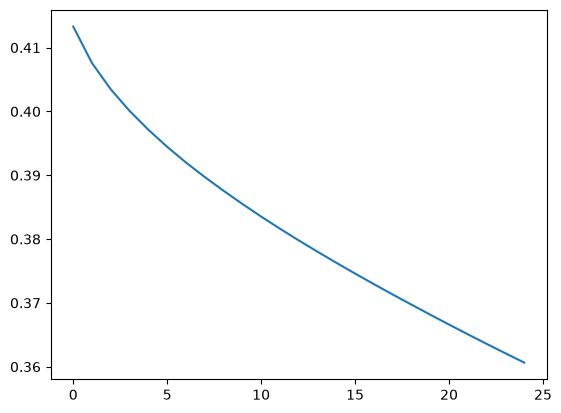

In [66]:
# plotting batch loss 
plt.plot(history_batch.history['loss'])

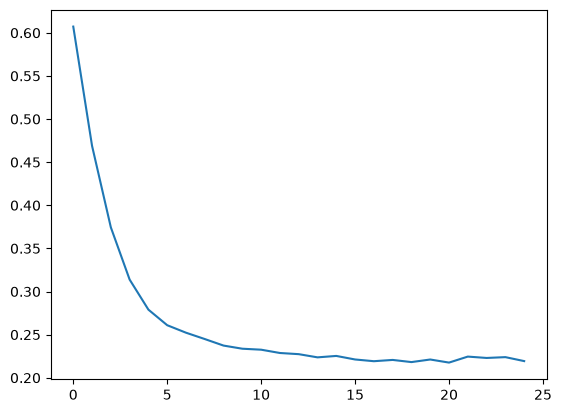

In [67]:
# plotting stochastic loss 
plt.plot(history_stochastic.history['loss'])

### iii - Mini-Batch GD 

-> Number of batches = (Number of rows in input data) / (Batch_size)<br>
-> Number of weight updates = (Number of batches) X (Number of epochs)<br>
-> Combines the capability of both Batch GD and Stochastic GD

In [69]:
mini_batch_model = Sequential() 

mini_batch_model.add(Dense(10,activation='relu',input_dim=3)) 
mini_batch_model.add(Dense(10,activation='relu')) 
mini_batch_model.add(Dense(1,activation='sigmoid'))

C:\Users\Sakriya Pyakurel\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [70]:
# mini batch model compiliation and training 
mini_batch_model.compile(loss='binary_crossentropy',metrics=['accuracy']) 
start = time.time() 
history_mini_batch=mini_batch_model.fit(X_train_scaled,Y_train,epochs=25,batch_size=16,validation_split=0.2)
print(time.time() - start)

Epoch 1/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.5859 - loss: 0.6545 - val_accuracy: 0.7031 - val_loss: 0.6083
Epoch 2/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6719 - loss: 0.6264 - val_accuracy: 0.7812 - val_loss: 0.5854
Epoch 3/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7578 - loss: 0.6016 - val_accuracy: 0.8906 - val_loss: 0.5625
Epoch 4/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8594 - loss: 0.5773 - val_accuracy: 0.9219 - val_loss: 0.5393
Epoch 5/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8906 - loss: 0.5519 - val_accuracy: 0.9062 - val_loss: 0.5149
Epoch 6/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9062 - loss: 0.5268 - val_accuracy: 0.9062 - val_loss: 0.4917
Epoch 7/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9219 - loss: 0.5029 - val_accuracy: 0.9062 - val_loss: 0.4689
Epoch 8/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9219 - loss: 0.4803 - val_accuracy: 0.9062 - va

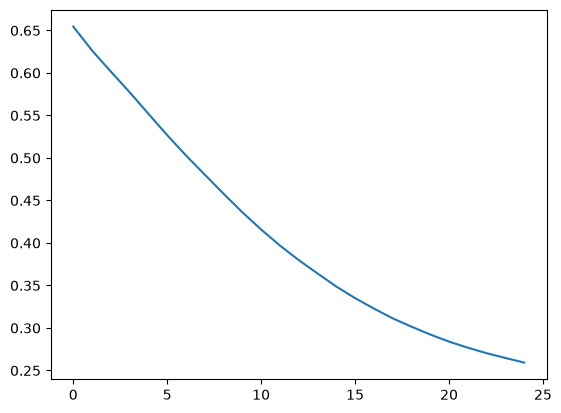

In [71]:
# plotting mini_batch loss 
plt.plot(history_mini_batch.history['loss'])